# Compression-05b — Recettes neuro-symboliques : le modèle découvre, le vérificateur certifie

**Navigation** : [Index de la série](README.md) | [Compression-05 — compression des modèles](Compression-05-MLCompression-Python.ipynb) | [Compression-06 — MDL](Compression-06-MDL-Kolmogorov-Python.ipynb)

> **Public : Licence.** Prérequis : [Compression-01](Compression-01-ShannonFano-Prefixe-Python.ipynb)
> (entropie, description d'une source) et les bases de Python. La lecture de
> [Compression-06](Compression-06-MDL-Kolmogorov-Python.ipynb) (coût d'une description) éclaire
> l'évaluation finale, mais le carnet se lit aussi directement après 01. Aucun service externe :
> tout est calculé localement, de façon déterministe.

Ce carnet déplie un sujet de recherche complet, jamais choisi par les groupes d'étudiants pour
lesquels il avait été écrit (sujet M9 du dépôt Epita 2026) : un **compresseur sans perte
neuro-symbolique** où un modèle de langage joue le rôle de *découvreur de régularités* — et
**jamais** celui de décodeur. L'idée directrice : au lieu de résumer les données (avec perte),
le découvreur propose une **recette de reconstruction** — un petit programme dans un langage
volontairement pauvre — telle que `données = decode(recette)` **exactement**, contrôlé par
empreinte. Un vérificateur symbolique fait le contrôle ; un décodeur **borné et total** exécute ;
un registre de recettes **signées** recycle le travail du découvreur pour les passages suivants.


## Le contrat de ce carnet

- **Quatre briques construites ici** : un DSL à pile façon Bitcoin Script (total : il refuse au
  lieu de boucler, budget de pas type gas/fuel) ; le round-trip certifié par empreinte SHA-256 ;
  un **découvreur énumératif** — la place exacte que le sujet donne à une cascade de LLM ; un
  **registre de recettes signées** façon antivirus (YARA/PRONOM), adressé par contenu.
- **Une mesure par brique** : coût d'une recette en bits, couverture du registre (taux
  d'opérations **sans** découvreur), recyclage sur la deuxième passe, refus mesuré d'une bombe
  de décompression, et l'arbitrage MDL face à `zlib`, `bz2` et `lzma`.
- **Le LLM reste dehors** : aucune clé, aucun appel réseau. Le contrat du proposant
  (échantillon → recettes candidates) est le même que celui d'une cascade de LLM ; c'est le
  vérificateur, symbolique et local, qui reste l'unique autorité — c'est le point central du
  sujet M9, et la différence avec [Compression-05](Compression-05-MLCompression-Python.ipynb),
  où le modèle compressé *est* l'objet, et avec le codage piloté par modèle de langage, où le
  modèle est *dans* le chemin de décodage.


In [1]:
import hashlib
import hmac
import json
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (9, 3.6)

N = 512  # taille commune des trois familles de données, en octets
print("imports OK — carnet 100 % hors ligne, déterministe (graines fixées)")

imports OK — carnet 100 % hors ligne, déterministe (graines fixées)


## 1. Le terrain : trois familles d'octets

Pour que l'arbitrage final soit lisible, les trois familles portent des régularités de natures
différentes :

- **`SUITE`** — une récurrence arithmétique modulo un premier : octet *i* = (7·*i* + 13) mod 251.
  La régularité est **algorithmique** : un programme de quelques instructions la régénère.
- **`TEXTE`** — un journal structuré (`cap=...;temp=...;`) dont les valeurs dérivent au hasard.
  La régularité est **statistique** : c'est le terrain des codecs du palier 03–04.
- **`ALEA`** — des octets pseudo-aléatoires : le témoin négatif, rien à extraire.


In [2]:
def suite_lineaire(a, b, p, n=N):
    return bytes((i * a + b) % p for i in range(n))

SUITE = suite_lineaire(7, 13, 251)

rng = random.Random(42)
_lignes, _cap = [], 1000
for _ in range(N // 2):
    _cap = max(950, min(1050, _cap + rng.randint(-8, 8)))
    _lignes.append(f"cap={_cap};temp={20 + rng.randint(-3, 3)};\n")
TEXTE = "".join(_lignes).encode("ascii")[:N]

ALEA = random.Random(2026).randbytes(N)

FAMILLES = {"SUITE": SUITE, "TEXTE": TEXTE, "ALEA": ALEA}
for nom, data in FAMILLES.items():
    print(f"{nom:6s} {len(data):4d} octets  tete={data[:16].hex()}"
          f"  empreinte={hashlib.sha256(data).hexdigest()[:12]}")

SUITE   512 octets  tete=0d141b222930373e454c535a61686f76  empreinte=2bb0920827d0
TEXTE   512 octets  tete=6361703d3939353b74656d703d31373b  empreinte=5d0f3edd56bb
ALEA    512 octets  tete=19a47e1e70bcc9515adfa480fc2f8bf3  empreinte=81fab3bee2a2


### Lecture.

La `SUITE` et le `TEXTE` font la même taille ; leurs régularités n'ont rien de commun. Un codec
statistique (Huffman, LZ) lit le `TEXTE` et s'ennuie sur la `SUITE` — chaque octet y apparaît
presque uniformément, la redondance vit dans la *loi de génération*, pas dans les fréquences.
C'est exactement la séparation que le sujet M9 exploite : un découvreur de **programmes** peut
voir ce qu'un codec de **symboles** ne voit pas.

## 2. Le DSL : une pile totale, bornée par construction

La recette est un programme d'une machine à pile volontairement pauvre, dans l'esprit de
Bitcoin Script — langage réel, délibérément non-Turing-complet (voir
[SC-20](../SymbolicAI/SmartContracts/05-Alternative-Chains/SC-20-Bitcoin-Scripting.ipynb)).
Notre copie pédagogique, déclarée comme telle, réduit l'idée à douze opcodes :

| Opcode | Effet | | Opcode | Effet |
|---|---|---|---|---|
| `PUSH n` | empile *n* (16 bits) | | `MOD` | dépile *b*, *a* ; empile *a* mod *b* |
| `ADD`/`SUB`/`MUL` | arithmétique (pile) | | `XOR` | ou-exclusif |
| `DUP`/`SWAP`/`DROP` | manipulations de pile | | `LEN` | empile la taille de la sortie **déjà émise** |
| `EMIT` | dépile *x* (0–255), l'émet | | `REP k [bloc]` | répète *k* fois un bloc — **déplié à l'analyse** |

Deux bornes font la **totalité** : `REP` est déplié *avant* l'exécution sous un plafond
d'instructions, et chaque instruction exécutée débite un **budget de pas** (le gas/fuel de
Script comme de Wasmtime — voir les références). Le décodeur ne peut ni boucler indéfiniment,
ni produire au-delà d'un plafond d'octets : il rend un verdict — des octets, ou un **refus
motivé**. `LEN` est l'équivalent déroulé d'un compteur de boucle : à la *i*-ième itération,
`LEN` vaut *i*. C'est lui qui donne à la machine le pouvoir de générer des suites.

In [3]:
FUEL_DEFAUT = 20_000        # budget de pas par exécution (le « gas » du DSL)
SORTIE_MAX_DEFAUT = 1_500   # plafond d'octets émis — réglage indépendant de la taille de programme
INSTR_MAX = 4_096           # taille maximale d'un programme APRÈS dépliage


class RecetteRefusee(Exception):
    """Échec contrôlé du décodeur. Le DSL est total : il refuse, il ne boucle pas."""

    def __init__(self, raison):
        super().__init__(raison)
        self.raison = raison


def deplier(prog):
    """Déplie les REP à l'analyse : il ne restera aucun while à l'exécution."""
    out = []

    def parcours(tokens):
        for t in tokens:
            if len(out) > INSTR_MAX:
                raise RecetteRefusee(f"programme déplié trop long (> {INSTR_MAX} instructions)")
            if t[0] == "REP":
                _, k, bloc = t
                if k < 0:
                    raise RecetteRefusee("REP négatif")
                if k > 0xFFFF:
                    raise RecetteRefusee("REP au-delà de 16 bits (borné à la sérialisation)")
                for _ in range(k):
                    parcours(bloc)
            else:
                out.append(t)

    parcours(prog)
    if len(out) > INSTR_MAX:
        raise RecetteRefusee(f"programme déplié trop long ({len(out)} > {INSTR_MAX})")
    return out


def decode(prog, fuel=FUEL_DEFAUT, sortie_max=SORTIE_MAX_DEFAUT):
    """Exécute une recette : pile d'entiers, sortie d'octets, budget de pas.
    Total par construction : un for borné par INSTR_MAX, aucun autre contrôle de boucle."""
    instrs = deplier(prog)
    pile, sortie = [], bytearray()
    for op in instrs:
        fuel -= 1
        if fuel < 0:
            raise RecetteRefusee("budget de pas épuisé")
        nom = op[0]
        if nom == "PUSH":
            pile.append(op[1] % (1 << 32))
        elif nom == "LEN":
            pile.append(len(sortie))
        elif nom == "EMIT":
            if not pile:
                raise RecetteRefusee("EMIT sur pile vide")
            x = pile.pop()
            if not 0 <= x < 256:
                raise RecetteRefusee(f"EMIT hors octet : {x}")
            if len(sortie) >= sortie_max:
                raise RecetteRefusee(f"plafond de sortie atteint ({sortie_max})")
            sortie.append(x)
        elif nom in ("ADD", "SUB", "MUL", "XOR"):
            if len(pile) < 2:
                raise RecetteRefusee(f"{nom} sur pile trop courte")
            b, a = pile.pop(), pile.pop()
            if nom == "ADD":
                pile.append((a + b) % (1 << 32))
            elif nom == "SUB":
                pile.append((a - b) % (1 << 32))
            elif nom == "MUL":
                pile.append((a * b) % (1 << 32))
            else:
                pile.append(a ^ b)
        elif nom == "MOD":
            if len(pile) < 2:
                raise RecetteRefusee("MOD sur pile trop courte")
            b, a = pile.pop(), pile.pop()
            if b == 0:
                raise RecetteRefusee("MOD par zéro")
            pile.append(a % b)
        elif nom == "DUP":
            if not pile:
                raise RecetteRefusee("DUP sur pile vide")
            pile.append(pile[-1])
        elif nom == "SWAP":
            if len(pile) < 2:
                raise RecetteRefusee("SWAP sur pile trop courte")
            pile[-1], pile[-2] = pile[-2], pile[-1]
        elif nom == "DROP":
            if not pile:
                raise RecetteRefusee("DROP sur pile vide")
            pile.pop()
        else:
            raise RecetteRefusee(f"opcode inconnu : {nom}")
    return bytes(sortie)


# --- Trois vérifications immédiates de la sémantique, avant toute prose ---
assert decode([("REP", 3, [("PUSH", 65), ("EMIT",)])]) == b"AAA"            # REP déplie
assert decode([("REP", 4, [("LEN",), ("EMIT",)])]) == bytes([0, 1, 2, 3])   # LEN vaut i
try:
    decode([("PUSH", 300), ("EMIT",)])
    raise AssertionError("EMIT hors octet aurait dû être refusé")
except RecetteRefusee as e:
    print("garde EMIT :", e.raison)
try:
    decode([("REP", 3, [("MOD",), ("EMIT",)])])
except RecetteRefusee as e:
    print("garde pile :", e.raison)
print("interpreteur OK — 12 opcodes, refus motivé plutôt que boucle")

garde EMIT : EMIT hors octet : 300
garde pile : MOD sur pile trop courte
interpreteur OK — 12 opcodes, refus motivé plutôt que boucle


### Lecture.

L'interpréteur tient en soixante-dix lignes : douze opcodes, un `for` borné, deux plafonds.
Chaque mode d'échec — pile vide, division par zéro, octet hors plage, budget, plafond de
sortie, programme trop long — rend un **refus motivé**, jamais un crash ni une attente. C'est
la propriété que le sujet M9 appelle un *décodeur borné, déterministe et total* : la même que
Bitcoin Script garantit en interdisant les boucles, et que Wasmtime garantit par son
*metering* (fuel). La certification du round-trip (section suivante) porte sur un décodeur
dont la terminaison ne fait pas de doute — c'est ce qui rend le certificat *vérifiable*.

## 3. Recettes et round-trip certifié

Une **recette** est un couple typé : soit un programme du DSL (avec ses bornes), soit une
**copie littérale** — la recette triviale qui stocke les octets tels quels. Le **vérificateur**
exécute la recette et compare les empreintes SHA-256 : c'est lui, symbolique et local, qui fait
autorité ; personne d'autre. La taille sérialisée d'une recette (octets d'opcodes + bornes)
est ce que l'évaluation MDL de la section 6 comptera comme *coût du modèle*.

In [4]:
CODES = {"ADD": 0x02, "SUB": 0x03, "MUL": 0x04, "MOD": 0x05, "XOR": 0x06,
        "DUP": 0x07, "SWAP": 0x08, "DROP": 0x09, "LEN": 0x0A, "EMIT": 0x0B}
# 0x01 = PUSH (2 octets littéraux), 0x0E = REP k + bloc + 0x0F (terminateur)


def serialiser(prog):
    """Sérialise une recette DSL en octets — pour mesurer sa taille, pas pour la relire."""
    def octets(tokens):
        out = bytearray()
        for t in tokens:
            nom = t[0]
            if nom == "PUSH":
                out.append(0x01)
                out += (t[1] & 0xFFFF).to_bytes(2, "little")
            elif nom == "REP":
                out.append(0x0E)
                out += (t[1] & 0xFFFF).to_bytes(2, "little")
                out += octets(t[2])
                out.append(0x0F)
            else:
                out.append(CODES[nom])
        return bytes(out)
    return bytes(octets(prog))


def executer_recette(r):
    if r["type"] == "literal":
        return r["octets"]
    return decode(r["prog"], r["fuel"], r["sortie_max"])


def verifier(donnees, r):
    """Le round-trip bit à bit : l'empreinte témoigne, l'égalité des octets prouve."""
    try:
        sortie = executer_recette(r)
    except RecetteRefusee as e:
        return False, f"recette refusée ({e.raison})"
    meme_empreinte = hashlib.sha256(sortie).hexdigest() == hashlib.sha256(donnees).hexdigest()
    if meme_empreinte and sortie == donnees:
        return True, "round-trip exact"
    return False, "sortie différente"


def recette_literal(donnees):
    return {"type": "literal", "octets": bytes(donnees)}


def taille_bits(r):
    if r["type"] == "literal":
        return 8 * (1 + len(r["octets"]))                    # étiquette + octets
    return 8 * (4 + len(serialiser(r["prog"])))              # bornes + programme


# --- la recette de SUITE, écrite à la main : LEN=7*i+13 mod 251, émis 512 fois ---
RECETTE_SUITE = {
    "type": "dsl",
    "prog": [("REP", N, [("LEN",), ("PUSH", 7), ("MUL",), ("PUSH", 13),
                         ("ADD",), ("PUSH", 251), ("MOD",), ("EMIT",)])],
    "fuel": FUEL_DEFAUT, "sortie_max": SORTIE_MAX_DEFAUT,
}
ok, info = verifier(SUITE, RECETTE_SUITE)
print(f"SUITE : round-trip {info}")
print(f"recette DSL   : {taille_bits(RECETTE_SUITE):5d} bits   programme sérialisé : "
      f"{len(serialiser(RECETTE_SUITE['prog']))} octets")
print(f"copie literal : {taille_bits(recette_literal(SUITE)):5d} bits")
print(f"rapport       : {taille_bits(recette_literal(SUITE)) / taille_bits(RECETTE_SUITE):.1f} x")

SUITE : round-trip round-trip exact
recette DSL   :   176 bits   programme sérialisé : 18 octets
copie literal :  4104 bits
rapport       : 23.3 x


### Lecture.

Une recette de 18 octets sérialisés (22 en comptant les bornes) régénère exactement 512
octets : le rapport de taille dépasse vingt, et l'exactitude n'est pas déclarée, elle est
**vérifiée** — empreinte et octets comparent la sortie au flux original. C'est le geste MDL du
palier 06 transporté dans un langage exécutable : le *modèle* est un programme, son *coût*
compte, et les données disparaissent dans sa seule exactitude. La copie littérale, elle,
reste la borne honnête : tout ce que le découvreur ne sait pas reconstruire coûte son propre
poids, plus une étiquette.

## 4. Le découvreur : énumérer une classe d'hypothèses

Le sujet M9 met ici une **cascade de LLM** (petit modèle d'abord, grand en dernier recours) :
à partir d'un échantillon, proposer des recettes candidates. Le carnet implémente la même
interface avec un proposant **énumératif et déterministe** : il parcourt une classe fermée
d'hypothèses — les récurrences linéaires (i·a + b) mod p et les suites constantes — et filtre
d'abord par le premier octet émis, exactement comme la cascade filtre par coût en tokens.
Le découvrable est borné ; le rôle, lui, est exactement celui du LLM dans l'architecture :
**proposer sans jamais être cru**. Chaque candidate passe par le vérificateur de la
section 3 ; si aucune ne convient, la sortie honnête est la copie littérale, pas une
approximation.

In [5]:
def proposer_lineaire(echantillon):
    """Génère les candidates de la classe (i*a + b) mod p, filtrées par le 1er octet.

    Le premier octet émis vaut b mod p : seuls les b congruents survivent — le même
    rôle d'économie que la cascade petit-modèle-d'abord du sujet M9.
    """
    n = len(echantillon)
    premier = echantillon[0]
    for p in (241, 251):
        for a in range(1, 13):
            for b in range(premier % p, 256, p):
                prog = [("REP", n, [("LEN",), ("PUSH", a), ("MUL",), ("PUSH", b),
                                    ("ADD",), ("PUSH", p), ("MOD",), ("EMIT",)])]
                yield {"type": "dsl", "prog": prog,
                       "fuel": FUEL_DEFAUT, "sortie_max": SORTIE_MAX_DEFAUT}


def proposer_constante(echantillon):
    n = len(echantillon)
    c = echantillon[0]
    prog = [("REP", n, [("PUSH", c), ("EMIT",)])]
    yield {"type": "dsl", "prog": prog, "fuel": FUEL_DEFAUT, "sortie_max": SORTIE_MAX_DEFAUT}


def decouvrir(donnees):
    """Cherche une recette exacte ; rend (recette, statistiques). Jamais d'approximation :
    en cas d'échec total, la sortie est la copie littérale."""
    stats = {"filtrees": 0, "verifiees": 0, "classe": None}
    for nom, prop in (("lineaire", proposer_lineaire), ("constante", proposer_constante)):
        for cand in prop(donnees):
            stats["filtrees"] += 1
            if taille_bits(cand) >= taille_bits(recette_literal(donnees)):
                continue                       # candidate plus lourde que la copie : inutile
            stats["verifiees"] += 1
            ok, _ = verifier(donnees, cand)
            if ok:
                stats["classe"] = nom
                return cand, stats
    return recette_literal(donnees), stats


resultats, stats_dec = {}, {}
for nom, data in FAMILLES.items():
    t0 = time.perf_counter()
    recette, st = decouvrir(data)
    dt = (time.perf_counter() - t0) * 1000
    ok, info = verifier(data, recette)
    resultats[nom], stats_dec[nom] = recette, st
    print(f"{nom:6s} classe={st['classe'] or 'copie literal':15s} "
          f"filtrees={st['filtrees']:4d} verifiees={st['verifiees']:3d} "
          f"{dt:6.1f} ms  bits={taille_bits(recette):5d}  [{info}]")

SUITE  classe=lineaire        filtrees=  31 verifiees= 31   62.3 ms  bits=  176  [round-trip exact]


TEXTE  classe=copie literal   filtrees=  25 verifiees= 25   49.3 ms  bits= 4104  [round-trip exact]


ALEA   classe=copie literal   filtrees=  25 verifiees= 25   47.0 ms  bits= 4104  [round-trip exact]


### Lecture.

Sur `SUITE`, le filtre du premier octet laisse quelques dizaines de candidates, la bonne est
certifiée en une fraction de seconde : la classe d'hypothèses était finie, l'énumération
suffit. Sur `TEXTE` et `ALEA`, la classe échoue **honnêtement** — le proposant rend la copie
littérale, jamais une reconstruction approchée. C'est précisément la division du travail du
sujet : quand la classe fermée ne suffit plus (structures, grammaires, formats), la cascade
de LLM propose hors grille —
[SL-7](../SymbolicAI/SymbolicLearning/SL-7-LLM-SymbolicLearning.ipynb) montre ce rôle
d'induction symbolique — mais le **verrou ne bouge pas** : le LLM propose, le vérificateur
dispose. Et si le modèle proposant est retiré, remplacé ou mis à jour, les recettes déjà
certifiées restent exactes : le modèle n'est **pas dans le chemin de décodage**.

## 5. Le registre de recettes : signatures, MAC, recyclage

L'innovation système du sujet M9 est un registre **façon antivirus** : à la manière de YARA
pour les maliciels ou de PRONOM/DROID pour les formats de fichiers, une **signature** — octets
de tête, n-grammes dominants — associe une famille de données à une **recette certifiée
signée**. Le chemin *casual* ne touche jamais le découvreur : la signature pré-filtre, la
recette signée est rejouée, l'empreinte tranche. Le découvreur — coûteux — n'intervient que
sur le **non reconnu**, et sa recette, une fois certifiée et signée, **enrichit le registre** :
son travail est recyclé en toute sécurité.

Nous signons avec un **HMAC** (clé symétrique) : c'est une simplification pédagogique,
déclarée — une vraie signature d'entrée de registre est asymétrique (Ed25519), pour que
n'importe qui vérifie sans détenir la clé d'émission. Le mécanisme, lui, est complet :
l'entrée est adressée par le contenu (son empreinte), son MAC couvre signature + empreinte +
recette, et le rejeu contrôle tout avant de dire « hit ».

In [6]:
CLE_REGISTRE = b"cle-pedagogique-05b"  # jouet ; une vraie clé d'émetteur reste secrète


def ngrammes(data, k=2, top=8):
    """Les k-grammes les plus fréquents — la partie « structure » de la signature."""
    c = Counter(data[i:i + k] for i in range(len(data) - k))
    return sorted(m.hex() for m, _ in c.most_common(top))


def signature(data):
    return {"prefixe": data[:8].hex(), "ngrammes": ngrammes(data)}


def corps_entree(entree):
    return json.dumps({k: entree[k] for k in ("sig", "empreinte", "recette")},
                      sort_keys=True).encode("utf-8")


def signer_entree(entree):
    entree["mac"] = hmac.new(CLE_REGISTRE, corps_entree(entree), hashlib.sha256).hexdigest()
    return entree


def enregistrer(registre, donnees, recette):
    entree = {"sig": signature(donnees),
              "empreinte": hashlib.sha256(donnees).hexdigest(),
              "recette": recette}
    signer_entree(entree)
    registre[entree["empreinte"]] = entree
    return entree


def detecter(registre, donnees):
    """Pré-filtre par signature : au moins la moitié des n-grammes de l'entrée en commun."""
    sig = signature(donnees)
    candidats = []
    for e in registre.values():
        communs = len(set(sig["ngrammes"]) & set(e["sig"]["ngrammes"]))
        if communs >= max(1, len(set(e["sig"]["ngrammes"])) // 2):
            candidats.append(e)
    return candidats


def rejouer(registre, donnees):
    """Le chemin casual : signature -> recette signée -> round-trip. Sans découvreur."""
    for e in detecter(registre, donnees):
        if hmac.new(CLE_REGISTRE, corps_entree(e), hashlib.sha256).hexdigest() != e["mac"]:
            return "REJETEE", "MAC invalide"
        ok, info = verifier(donnees, e["recette"])
        if ok:
            return "HIT", e["empreinte"][:12]
    return "MISS", None


# --- le registre part d'une seule famille rencontrée : SUITE (7, 13, 251) ---
registre = {}
enregistrer(registre, SUITE, resultats["SUITE"])
print(f"registre initial : {len(registre)} entree(s)")

# corpus de test : la famille connue, plus trois inconnues (autre longueur, autres parametres)
CORPUS_TEST = [
    ("SUITE connue", suite_lineaire(7, 13, 251)),
    ("SUITE autre N", suite_lineaire(7, 13, 251, n=384)),
    ("SUITE (11,5,251)", suite_lineaire(11, 5, 251)),
    ("SUITE (9,29,241)", suite_lineaire(9, 29, 241)),
]

verdicts, appels_decouvreur = [], 0
for nom, data in CORPUS_TEST:
    verdict, detail = rejouer(registre, data)
    if verdict == "MISS":                      # non reconnu : on paie le découvreur
        appels_decouvreur += 1
        recette, _ = decouvrir(data)
        ok, info = verifier(data, recette)
        if ok and recette["type"] == "dsl":
            enregistrer(registre, data, recette)   # certifiée -> signée -> recyclable
            verdict = "HIT (apres decouverte)"
        else:
            verdict = "SANS RECETTE (copie literal)"
    verdicts.append(verdict)
    print(f"passe 1  {nom:16s} {verdict}")
# KPI du sujet : taux d'operations realisees SANS decouvreur — seuls les HIT
# du premier essai comptent ; les decouvertes enrichissent, elles ne couvrent pas.
couverture = sum(v == "HIT" for v in verdicts) / len(verdicts)
print(f"passe 1 : couverture sans decouvreur {couverture:.0%}, decouvreurs appels : "
      f"{appels_decouvreur}, registre : {len(registre)} entrees")

registre initial : 1 entree(s)
passe 1  SUITE connue     HIT
passe 1  SUITE autre N    HIT (apres decouverte)


passe 1  SUITE (11,5,251) HIT (apres decouverte)
passe 1  SUITE (9,29,241) HIT (apres decouverte)
passe 1 : couverture sans decouvreur 25%, decouvreurs appels : 3, registre : 4 entrees


In [7]:
# --- passe 2 : les memes flux reviennent -- mesurons le recyclage ---
verdicts2, appels2 = [], 0
for nom, data in CORPUS_TEST:
    verdict, detail = rejouer(registre, data)
    if verdict == "MISS":
        appels2 += 1
    verdicts2.append(verdict)
    print(f"passe 2  {nom:16s} {verdict}")
couverture2 = sum(v.startswith("HIT") for v in verdicts2) / len(verdicts2)
print(f"passe 2 : couverture {couverture2:.0%}, decouvreurs appels : {appels2}")

passe 2  SUITE connue     HIT
passe 2  SUITE autre N    HIT
passe 2  SUITE (11,5,251) HIT
passe 2  SUITE (9,29,241) HIT
passe 2 : couverture 100%, decouvreurs appels : 0


### Lecture.

Première passe : une famille sur quatre est servie **sans** découvreur — les trois inconnues
le paient, leurs recettes certifiées entrent au registre. Deuxième passe, les mêmes flux
reviennent : **couverture totale, zéro appel au découvreur**. C'est le résultat central du
sujet M9, mesuré : le travail coûteux est payé une fois, signé, puis **recyclé** — pour un
utilisateur casual, compresser et décompresser se font la plupart du temps sans aucun modèle.
La signature ne *décide* jamais : elle pré-filtre ; c'est l'empreinte du round-trip qui dit
« hit », exactement comme un antivirus n'identifie un fichier que si la signature **et** le
contenu concordent.

## 6. L'arbitrage MDL : recettes contre codecs

Le critère du sujet est la **longueur de description minimale** — le palier
[06](Compression-06-MDL-Kolmogorov-Python.ipynb) en pose la théorie ; ici il arbitre entre
représentations sur les mêmes flux : la recette (DSL ou copie littérale, bornes comprises)
face aux codecs présents dans la bibliothèque standard, `zlib`, `bz2`, `lzma`. Le sujet vise
aussi `zstd` et `ZPAQ` : absents de l'environnement de ce carnet, leur comparaison est le
terrain de [04b](Compression-04b-CodecsSOTA-Pareto-Python.ipynb) — l'arbitrage ci-dessous se
limite aux codecs exécutables ici, et le dit.

In [8]:
import bz2
import lzma
import zlib

lignes = []
for nom, data in FAMILLES.items():
    recette = resultats[nom]
    lignes.append({
        "famille": nom,
        "recette (bits)": taille_bits(recette),
        "zlib (bits)": 8 * len(zlib.compress(data, 9)),
        "bz2 (bits)": 8 * len(bz2.compress(data, 9)),
        "lzma (bits)": 8 * len(lzma.compress(data)),
        "copie (bits)": taille_bits(recette_literal(data)),
    })
tb = pd.DataFrame(lignes).set_index("famille")
meilleur = tb.idxmin(axis=1)
tb = tb.round(0).astype(int)
print(tb.assign(meilleur=meilleur.values).to_string())

         recette (bits)  zlib (bits)  bz2 (bits)  lzma (bits)  copie (bits)        meilleur
famille                                                                                    
SUITE               176         2216        3976         2464          4104  recette (bits)
TEXTE              4104          968        1032         1344          4104     zlib (bits)
ALEA               4104         4184        5376         4576          4104  recette (bits)


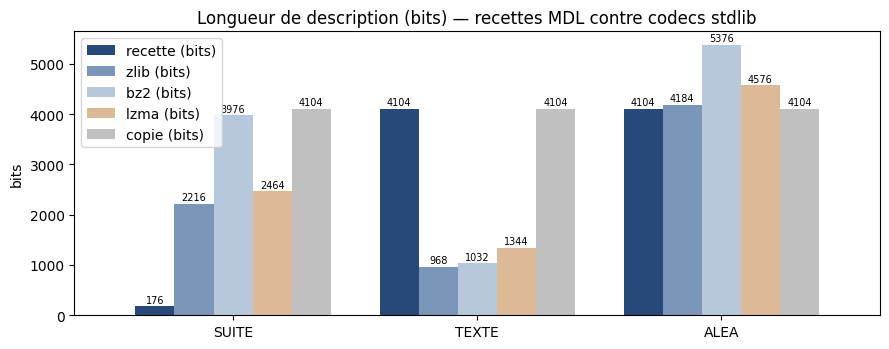

In [9]:
ax = tb.plot(kind="bar", rot=0, width=0.8,
            color=["#28487a", "#7a96b8", "#b8c8dc", "#dcba96", "#c0c0c0"])
ax.set_title("Longueur de description (bits) — recettes MDL contre codecs stdlib")
ax.set_ylabel("bits")
ax.set_xlabel("")
for conteneur in ax.containers:
    ax.bar_label(conteneur, fontsize=7, padding=1)
plt.tight_layout()
plt.show()

### Lecture.

Sur la `SUITE`, la recette écrase les trois codecs : ceux-ci lisent des fréquences et des
répétitions littérales que la loi de génération ne laisse pas voir — `zlib` rend à peine
mieux que la copie. Sur le `TEXTE`, c'est l'inverse : la régularité est statistique, le
terrain natif des codecs, et aucune recette de notre classe n'existe — la copie littérale
perd nettement face à `zlib`. Détail instructif : à 512 octets, `lzma` perd contre `zlib`
et `bz2` — l'en-tête et le modèle pèsent plus que leur gain ; la taille du bloc compte
autant que le codec, c'est une des leçons du palier 06. Sur `ALEA`, tout le monde paie
l'en-tête (la « recette » retenue y est la copie elle-même) : personne n'extrait ce qui
n'y est pas. Le verdict est la **séparation des régularités** : algorithmique d'un côté
(programme court), statistique de l'autre (modèle de symboles) — et le sujet M9 est
précisément l'architecture qui refuse de choisir, en mettant les deux dans le même registre
sous le même critère.

## 7. Robustesse : la bombe de décompression est refusée, pas subie

Une archive auto-descriptive qui embarque son décodeur (VXA, ZPAQ — voir références) doit
répondre d'une question : que se passe-t-il quand la recette est **malveillante** ? Les bornes
de la section 2 ne sont pas décoratives — vérifions-les sur trois attaques : un programme qui
veut produire au-delà du plafond de sortie, un budget de pas volontairement étranglé, et un
programme dont le dépliage dépasserait la taille maximale. Chaque attaque doit rendre un
refus motivé en temps **borné mesuré**, sans exception non contrôlée.

In [10]:
attaques = {
    "plafond de sortie": {"type": "dsl",
        "prog": [("REP", 1_600, [("PUSH", 65), ("EMIT",)])],
        "fuel": FUEL_DEFAUT, "sortie_max": SORTIE_MAX_DEFAUT},
    "budget de pas": {"type": "dsl",
        "prog": [("REP", 1_600, [("PUSH", 65), ("EMIT",)])],
        "fuel": 100, "sortie_max": SORTIE_MAX_DEFAUT},
    "depliage maximal": {"type": "dsl",
        "prog": [("REP", 60_000, [("PUSH", 65), ("EMIT",)])],
        "fuel": FUEL_DEFAUT, "sortie_max": SORTIE_MAX_DEFAUT},
}
for nom, bombe in attaques.items():
    t0 = time.perf_counter()
    try:
        sortie = executer_recette(bombe)
        verdict = f"EXECUTEE ({len(sortie)} octets)"
    except RecetteRefusee as e:
        verdict = f"REFUSEE ({e.raison})"
    dt = (time.perf_counter() - t0) * 1_000
    print(f"{nom:18s} {verdict:52s} {dt:7.2f} ms")

plafond de sortie  REFUSEE (plafond de sortie atteint (1500))              2.48 ms
budget de pas      REFUSEE (budget de pas épuisé)                          1.23 ms
depliage maximal   REFUSEE (programme déplié trop long (> 4096 instructions))    1.48 ms


### Lecture.

Trois attaques, trois refus motivés, chacun en temps borné — quelques millisecondes, dont
l'essentiel est la construction de l'exception. Aucun `while` ne tourne à l'exécution : la
garde vit dans le dépliage (taille maximale), dans le budget de pas et dans le plafond
d'émission. C'est la propriété anti-bombe que le sujet exige du décodeur certifié : un
archiveur qui embarque des programmes inconnus doit pouvoir les exécuter **en cage**, et la
cage doit être vérifiable avant l'exécution — pas espérée pendant.

## À retenir

| Résultat | Mesure |
|---|---|
| Le modèle n'est **pas dans le chemin de décodage** | le LLM/découvreur propose ; le vérificateur symbolique local est l'unique autorité |
| La régularité algorithmique est invisible des codecs | `SUITE` : recette 176 bits contre ~4 100 pour `zlib`/copie |
| La régularité statistique reste aux codecs | `TEXTE` : `zlib` gagne (968 bits), aucune recette de la classe n'existe |
| Le registre recycle le travail coûteux | passe 1 : 1/4 **sans** découvreur, 3 découvertes ; passe 2 : couverture 100 %, **0** appel |
| Le décodeur est total et borné | 3 attaques, 3 refus motivés en temps borné mesuré |

## Limites honnêtes (copies pédagogiques déclarées)

1. **DSL jouet contre Bitcoin Script** : douze opcodes contre un langage réel déployé —
   copie pédagogique déclarée, motif : montrer la totalité par construction ;
   [SC-20](../SymbolicAI/SmartContracts/05-Alternative-Chains/SC-20-Bitcoin-Scripting.ipynb)
   développe le langage réel.
2. **HMAC symétrique contre signature asymétrique** : le registre pédagogique signe avec une
   clé partagée ; une entrée publiable exige Ed25519 (n'importe qui vérifie, seul l'émetteur
   signe) — l'exercice 3 prépare le contrôle, la cryptographie reste à brancher.
3. **Découvreur énumératif contre cascade de LLM** : la classe d'hypothèses est fermée
   (récurrences linéaires, constantes) ; le sujet vise des découvertes hors grille par LLM —
   le contrat d'interface (échantillon → candidates → vérification) est le même, l'étendue
   non.
4. **Codecs stdlib contre `zstd`/`ZPAQ`** : absents de cet environnement, comparés dans
   [04b](Compression-04b-CodecsSOTA-Pareto-Python.ipynb).
5. **MDL calculable contre Kolmogorov** : nos 176 bits sont une description *trouvée*, pas
   la complexité idéale — [06](Compression-06-MDL-Kolmogorov-Python.ipynb) creuse l'écart.
6. **Certification par round-trip contre preuve formelle** : le vérificateur contrôle
   l'exactitude d'une exécution ; il ne prouve pas la conformité du décodeur à une
   spécification — la note de cadrage du sujet juge la voie Lean (Lean-14b, SC-14, SC-15)
   surdimensionnée pour ce carnet ; elle reste la référence pour aller plus loin.

## Références

Le sujet M9 (« Compresseur sans perte neuro-symbolique : LLM-découvreur, décodeur certifié
et registre de recettes signées », dépôt Epita 2026, difficulté 5/5, jamais choisi) est la
source primaire de ce carnet — lue intégralement à la source, y compris sa table de
notebooks CoursIA et sa bibliographie. Mentions de fond, lues comme rappels de contexte et
non comme résultats attribués ici : Solomonoff (1964) et Rissanen (1978) pour
l'induction-par-compression et le MDL ; Li et Vitanyi pour la complexité de Kolmogorov ; le
Hutter Prize pour la compression-sans-perte-comme-mesure ; le sujet M9 *rapporte* (Deletang
et al., 2024 ; Bellard NNCP/ts_zip) que le codage piloté par modèle de langage atteint
d'excellents taux **en exigeant le modèle exact au décodage** — la contrainte que
l'architecture de ce carnet retire ; Ford (VXA, 2005) et Mahoney (ZPAQ) pour les archives
embarquant leur décodeur borné ; Necula (Proof-Carrying Code, 1997) pour le code qui porte
sa preuve ; YARA et PRONOM/DROID pour les registres de signatures ; Wasmtime pour le
metering par fuel.


## 8. Exercices

Les trois exercices étendent les briques du carnet. Ils se traitent **sans modifier les
cellules déjà exécutées** : recopiez la fonction dans la cellule de l'exercice, complétez-la,
et les assertions de contrôle vous diront si le résultat est juste. Les stubs s'exécutent
sans erreur — ils rendent `None`, et les contrôles affichent simplement « à compléter ».

### Exercice 1 — Un opcode `FILL`, et la recette d'une suite plate

Le DSL n'a pas d'opcode d'émission en bloc. Ajoutez `FILL` : il dépile `n` puis `v` et émet
`n` copies de l'octet `v` (bornes de pile et plafond de sortie compris). Écrivez ensuite la
recette de `PLATE = bytes(512 * [7])` et vérifiez le round-trip : elle doit être plus courte
que la copie littérale.

In [11]:
def decode_avec_fill(prog, fuel=FUEL_DEFAUT, sortie_max=SORTIE_MAX_DEFAUT):
    """Comme decode, avec l'opcode FILL en plus.

    Etape 1 : dans une copie de la boucle d'execution, ajoutez la branche FILL —
              deux depilements (n puis v), memes gardes qu'EMIT (plafond, plage 0-255).
    Etape 2 : construire la recette de PLATE avec un seul FILL.
    """
    # TODO etudiant : copier la boucle de decode et ajouter FILL
    return None


PLATE = bytes(512 * [7])
recette_plate = None  # TODO etudiant : [(PUSH, 512), (PUSH, 7), (FILL,)] attendu
_fill_ok = decode_avec_fill([("PUSH", 3), ("PUSH", 65), ("FILL",)]) == b"AAA"
if _fill_ok and recette_plate is not None:
    print("FILL OK ; recette PLATE :", verifier(PLATE, recette_plate))
elif _fill_ok:
    print("Exercice 1 a completer (recette PLATE)")
else:
    print("Exercice 1 a completer (opcode FILL)")

Exercice 1 a completer (opcode FILL)


### Exercice 2 — Une classe d'hypothèses de plus : la périodicité

`TEXTE` est régulier par **périodes** (les lignes se répètent à structure près), hors de la
classe du découvreur de la section 4. Écrivez `recette_periodique(data, p_max)` : pour chaque
période `p` ≤ `p_max`, la candidate est « bloc littéral des `p` premiers octets, répété
`len(data)//p` fois » — encodable en DSL par un `REP` d'un bloc de `PUSH`/`EMIT`, ou par une
recette étendue de votre cru. La candidate n'est retenue que si le round-trip est **exact**.

In [12]:
def recette_periodique(data, p_max=32):
    """Cherche une periode exacte p <= p_max et rend la recette DSL correspondante.

    Etape 1 : pour chaque p, extraire la periode candidate data[:p] et verifier que
              data == data[:p] * (len(data) // p) + data[:len(data) % p] est FAUX en general :
              une periode exacte n'existe que si len(data) % p == 0 et la tuile se repete.
    Etape 2 : encoder la tuile en bloc PUSH/EMIT dans un REP, bornes comprises.
    Retour : la recette si le round-trip est exact, sinon None.
    """
    # TODO etudiant
    return None


PLATE2 = bytes(b"ABCD" * 64)  # 256 octets, periode 4 exacte
rp = recette_periodique(PLATE2)
if rp is not None and verifier(PLATE2, rp)[0]:
    print("recette periodique OK :", taille_bits(rp), "bits contre",
          taille_bits(recette_literal(PLATE2)), "en copie")
else:
    print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 — Le contrôle d'entrée du registre

Une entrée du registre est acceptée seulement si **tout** concorde : le MAC recalculé, le
round-trip de la recette, et l'empreinte annoncée. Écrivez `verifier_entree(entree, cle)` qui
rend un verdict motivé — c'est le contrôle qu'un pair exécuterait avant de rejouer une recette
publiée par un tiers, et l'endroit où une vraie signature asymétrique (Ed25519) se brancherait
à la place du HMAC.

In [13]:
def verifier_entree(entree, cle=CLE_REGISTRE):
    """Controle complet d'une entree de registre avant rejeu par un tiers.

    Etape 1 : recalculer le MAC sur (sig, empreinte, recette) et le comparer au champ mac.
    Etape 2 : la recette doit etre autoportante — executer et comparer les empreintes.
    Retour : (True, "entree valide") ou (False, raison).
    """
    # TODO etudiant
    return None


_entree_saine = registre[hashlib.sha256(SUITE).hexdigest()]
_entree_falsifiee = dict(_entree_saine)
_entree_falsifiee["empreinte"] = "00" * 32   # une empreinte menteuse
v1 = verifier_entree(_entree_saine)
v2 = verifier_entree(_entree_falsifiee)
if v1 is not None:
    print("entree saine :", v1)
    print("entree falsifiee :", v2)
else:
    print("Exercice 3 a completer")

Exercice 3 a completer
